In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [104]:
cities = pd.read_csv("../data/cities.csv")
stations = pd.read_csv("../data/stations.csv")
trips = pd.read_csv("../data/trips_small.csv")


In [105]:
print(cities.shape)
print(stations.shape)
print(trips.shape)


(267, 7)
(2932, 11)
(1161376, 13)


In [106]:
cities.head()

,id,name,lat,lon,timezone,country,return_to_official_only
0,220,Zagreb,45.7984,15.98810,Europe/Berlin,HR,True
1,431,Kalisz,51.7525,18.03410,Europe/Warsaw,PL,True
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True
3,519,Siemianowice Śląskie,50.3031,19.02220,Europe/Warsaw,PL,True
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False


In [107]:
stations.head()

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat
0,142186362,135,BIKE 500100,0,NaN,12,0,0,NaN,7.821669,51.677449
1,940986,176,Bahnhof Trassenmoor 5525,5525,NaN,0,6,0,NaN,13.868973,54.090538
2,93646685,176,Mutter/Vater-Kind-Kurklinik Haus Möwennest Zin...,5529,stele,0,15,0,NaN,13.918970,54.073088
3,111365509,243,Station Road,8494,smart_sign,0,20,0,NaN,-3.936120,56.119272
4,405835,302,Birkirkara Road,6868,sign,0,6,0,NaN,14.481456,35.906836


In [108]:
trips.head()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993


# Task 1: Data Exploration and Preprocessing

## Preprocessing

Can I make the categorization here?

In [109]:
# 90 s: 0 excluded
trips[trips["duration"] < 90]

# distance 50m - 20km: 0 excluded
trips[trips["distance"] < 50]

# coordinates
# TODO

# reasonable cycling speed (distance /duration) [0.25, 15]km/h : 745, but all 15.0x
trips["cycling speed"] = (trips["distance"] / trips["duration"]) * 3.6 # m/s to km/h

trips[trips["cycling speed"] > 15]

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance,cycling speed
3440,11418,7,1.668170e+09,8.216180,50.095700,8.240044,50.079147,4775153.0,87796213.0,NaN,NaN,600.0,2507.309844,15.043859
39209,23961,639,1.662524e+09,19.702693,52.569308,19.698110,52.560750,33277348.0,13696183.0,NaN,NaN,240.0,1000.756865,15.011353
44932,26658,461,1.662720e+09,21.052146,52.099320,21.050553,52.137604,5445524.0,2585904.0,NaN,NaN,1020.0,4258.381679,15.029582
47297,30657,639,1.662444e+09,19.704077,52.540313,19.768780,52.514090,33279339.0,13696021.0,NaN,NaN,1261.0,5259.415408,15.014985
49165,30137,505,1.661920e+09,7.879364,48.341468,7.835329,48.340131,10563355.0,8275890.0,NaN,NaN,780.0,3258.073511,15.037262
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1159232,826059,679,1.664879e+09,-3.185756,51.429879,-3.163247,51.465538,86312067.0,88102363.0,100.0,100.0,1020.0,4260.899309,15.038468
1159864,825616,679,1.662289e+09,-3.185756,51.429879,-3.163247,51.465538,86312067.0,88102363.0,100.0,100.0,1020.0,4260.899309,15.038468
1160009,825621,679,1.676561e+09,-3.185756,51.429879,-3.163247,51.465538,86312067.0,88102363.0,100.0,98.0,1021.0,4260.899309,15.023739
1161195,840037,679,1.674808e+09,-3.185756,51.429879,-3.163247,51.465538,86312067.0,88102363.0,100.0,85.0,1020.0,4260.899309,15.038468


## Exploration



Some bikes are counted more than once, becasue they appeared in different cities. We don't want to count a bike more than onece. which means we need to assign a primary city for a bike.

In [122]:
counted_twice = trips.groupby("bike_id")["city_id"].nunique().reset_index()
counted_twice.city_id.value_counts()

city_id
1     19115
2      3879
4      1661
3      1405
5       242
6        90
7        24
8         7
10        1
Name: count, dtype: int64

The data set comprises 267 cities with 26424 bikes in total.

In [126]:
print("Number of Cities:", cities["id"].nunique())
print("Number of Bikes:",trips["bike_id"].nunique())

Number of Cities: 267
Number of Bikes: 26424


## Fig 4 (Method A)

### Fig 4.1 Distribution of (average) Bikes per Station

**Define the hierarchy of the problem: System (city) level  --> station level --> bike level**

Each city is a bike sharing system (BBS). Each BBS has multiple stations.

Bikes per station is calculated at the system level. The approach is:
- get n_bikes per city
- get n_stations per city
- dividing n_bikes by n_stations, thus get the average n_bikes per station in each city.

Note that only station-based BSS are concerned in this question. A BSS is considered station-based if city.return_to_ifficial_only == True. If a BBS is not station-based then it is free-floating.

stations.city_id <--> cities.id
trips.city_id <--> cities.id

In [111]:
city_bikes = (
    trips.groupby("city_id")["bike_id"]
    .nunique()
    .reset_index(name="n_bikes")
)
city_bikes

,city_id,n_bikes
0,7,456
1,23,97
2,64,424
3,88,321
4,128,235
...,...,...
180,835,60
181,848,1364
182,853,1338
183,856,1302


In [112]:
city_stations = (
    stations.groupby("city_id")["id"]
    .count()
    .reset_index(name="n_stations")
)
city_stations

,city_id,n_stations
0,7,37
1,23,29
2,64,44
3,88,41
4,128,44
...,...,...
180,835,21
181,848,11
182,853,6
183,856,10


In [113]:
df2 = cities.merge(city_bikes, left_on="id", right_on="city_id").drop(columns="id")
df2 = df2.merge(city_stations, on="city_id")

# select station-based systems only
df2 = df2[df2["return_to_official_only"] == True]

df2["bikes_per_station"] = df2["n_bikes"] / df2["n_stations"]
# Categorize system size

def categorize_size(n):
    if n > 500:
        return "large"
    elif n >= 101:
        return "medium"
    elif n >= 10:
        return "small"
    return None

df2["system_size"] = df2["n_bikes"].apply(categorize_size)
df2 = df2.dropna(subset=["system_size"])


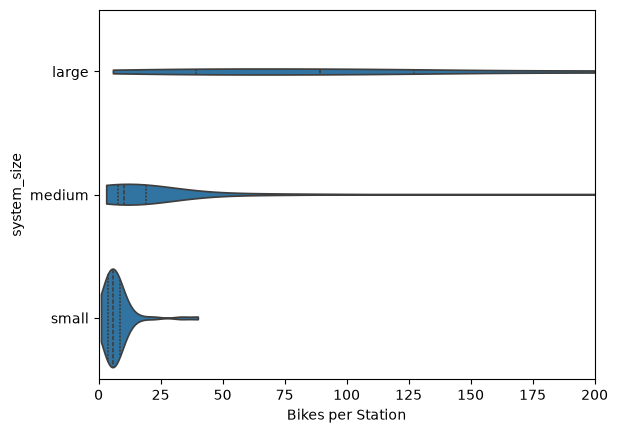

In [114]:
# violin plot
sns.violinplot(
    data=df2,
    x="bikes_per_station",
    y="system_size",
    order=["large", "medium", "small"],
    inner="quartile",
    cut=0
)
plt.xlabel("Bikes per Station")
plt.xlim(0,200)
plt.show()

# Very different from paper. Different data?

## Fig 4.2 Bikes per Rack

Also calculated at city level, similar appraoch to the average number of bikes per station. Again we consider station-based BSS only. And we also need to exclude cities with no racks, since dividing by 0 is invalid.

We noticed that special racks has negative values. Using AI to search info: there are two reporting schemes from Nextbike. If special_racak is positive, bike_racks means regular racks; if negative, bike_racks means number of total racks, the "-" sign means reserved for charging e-bikes. 

In [115]:
# calculate total number of racks in each station
stations["total_racks"] = np.where(
    stations["special_racks"] < 0,
    stations["bike_racks"],                                      # subtractive: bike_racks is already gross total
    stations["bike_racks"] + stations["special_racks"].fillna(0) # additive: add both
)

# city_bikes we already have, now calculate city_racks
city_racks = (
    stations.groupby("city_id")["total_racks"]
    .sum()
    .reset_index(name="n_racks")
)

# merge city_racks and city
df2 = cities.merge(city_racks, left_on="id", right_on="city_id")
# then merge with city_bikes
df2 = df2.merge(city_bikes, on="city_id")

# select station-based systems only
df2 = df2[df2["return_to_official_only"] == True]

# exclude 0 n_racks
df2 = df2[df2["n_racks"] > 0]

# calculate bikes_per_rack
df2["bikes_per_rack"] = df2["n_bikes"] / df2["n_racks"]

# again, categorize
def categorize_size(n):
    if n > 500:
        return "large"
    elif n >= 101:
        return "medium"
    elif n >= 10:
        return "small"
    return None

df2["system_size"] = df2["n_bikes"].apply(categorize_size)

df2.describe()

,id,lat,lon,city_id,n_racks,n_bikes,bikes_per_rack
count,125.000000,125.000000,125.000000,125.000000,125.000000,125.000000,125.000000
mean,558.304000,49.122666,12.712983,558.304000,128.520000,222.008000,3.579096
std,198.014346,4.656496,7.433372,198.014346,164.676986,301.083728,6.777419
min,128.000000,27.815400,-15.518200,128.000000,4.000000,1.000000,0.035714
25%,431.000000,46.252900,8.351640,431.000000,34.000000,52.000000,0.677019
50%,562.000000,50.622200,15.163500,562.000000,79.000000,111.000000,1.095238
75%,727.000000,52.040600,18.738200,727.000000,154.000000,233.000000,2.831250
max,856.000000,56.945300,24.103300,856.000000,1256.000000,1554.000000,51.100000


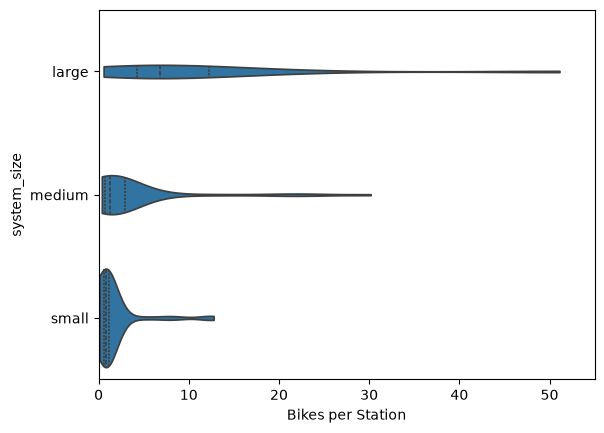

In [116]:
# violin plot
sns.violinplot(
    data=df2,
    x="bikes_per_rack",
    y="system_size",
    order=["large", "medium", "small"],
    inner="quartile",
    cut=0
)
plt.xlabel("Bikes per Station")
plt.xlim(0, 55)
plt.show()